# 2. Joint entropy and conditional entropy

**Cover and Thomas, Section 2.2.**

For a pair $(X, Y) \sim p(x,y)$,

$$H(X,Y) = -\sum_{x}\sum_{y} p(x,y) \log p(x,y),$$

$$H(Y \mid X) = \sum_x p(x)\, H(Y \mid X = x)
= -\sum_x \sum_y p(x,y) \log p(y \mid x).$$

Note the asymmetry in the second definition: $H(Y \mid X)$ is the *average*
over $x$ of the entropy of the conditional distribution of $Y$ given $X = x$.

**Theorem 2.2.1 (chain rule).** $H(X,Y) = H(X) + H(Y \mid X)$.

**Corollary.** $H(X,Y \mid Z) = H(X \mid Z) + H(Y \mid X, Z)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import infotools as it

it.setup_plot_style()
rng = np.random.default_rng(1)

## 2.1 How a joint distribution is stored

A joint distribution is a 2-D numpy array `P` with

`P[i, j]` $= p(X = i+1,\; Y = j+1)$,

so **rows are values of $X$** and **columns are values of $Y$**. Summing over
the columns gives the marginal of $X$; summing over the rows gives the
marginal of $Y$.

In [2]:
P = np.array([[0.30, 0.10],
              [0.15, 0.45]])

print("the joint table P[i, j] = p(x_i, y_j):")
print(P)
print()
print("p(x) = row sums    =", P.sum(axis=1))
print("p(y) = column sums =", P.sum(axis=0))
print("total              =", P.sum())

the joint table P[i, j] = p(x_i, y_j):
[[0.3  0.1 ]
 [0.15 0.45]]

p(x) = row sums    = [0.4 0.6]
p(y) = column sums = [0.45 0.55]
total              = 1.0


## 2.2 Example 2.2.1 of the book

$$
p(x,y) =
\begin{array}{c|cccc}
 & x=1 & x=2 & x=3 & x=4 \\ \hline
y=1 & 1/8 & 1/16 & 1/32 & 1/32 \\
y=2 & 1/16 & 1/8 & 1/32 & 1/32 \\
y=3 & 1/16 & 1/16 & 1/16 & 1/16 \\
y=4 & 1/4 & 0 & 0 & 0
\end{array}
$$

The book writes $x$ across the top, so we type the table exactly as printed
and then transpose it to match our row-is-$X$ convention.

In [3]:
book_table = np.array([
    [1/8,  1/16, 1/32, 1/32],   # y = 1
    [1/16, 1/8,  1/32, 1/32],   # y = 2
    [1/16, 1/16, 1/16, 1/16],   # y = 3
    [1/4,  0,    0,    0   ],   # y = 4
])
P = book_table.T                # P[i, j] = p(X = i+1, Y = j+1)

it.show_table(P)

X\Y           1        2        3        4       p(x)
    1    0.1250   0.0625   0.0625   0.2500     0.5000
    2    0.0625   0.1250   0.0625   0.0000     0.2500
    3    0.0312   0.0312   0.0625   0.0000     0.1250
    4    0.0312   0.0312   0.0625   0.0000     0.1250
 p(y)    0.2500   0.2500   0.2500   0.2500     1.0000


In [4]:
H_X   = it.entropy(it.marginal_X(P))
H_Y   = it.entropy(it.marginal_Y(P))
H_XY  = it.joint_entropy(P)
H_X_g_Y = it.cond_entropy_X_given_Y(P)
H_Y_g_X = it.cond_entropy_Y_given_X(P)

print(f"H(X)    = {H_X:.6f}   book: 7/4  = {7/4}")
print(f"H(Y)    = {H_Y:.6f}   book: 2")
print(f"H(X|Y)  = {H_X_g_Y:.6f}   book: 11/8 = {11/8}")
print(f"H(Y|X)  = {H_Y_g_X:.6f}   book: 13/8 = {13/8}")
print(f"H(X,Y)  = {H_XY:.6f}   book: 27/8 = {27/8}")

H(X)    = 1.750000   book: 7/4  = 1.75
H(Y)    = 2.000000   book: 2
H(X|Y)  = 1.375000   book: 11/8 = 1.375
H(Y|X)  = 1.625000   book: 13/8 = 1.625
H(X,Y)  = 3.375000   book: 27/8 = 3.375


## 2.3 Where $H(X \mid Y)$ comes from, term by term

The book computes

$$H(X \mid Y) = \tfrac14 H\!\left(\tfrac12,\tfrac14,\tfrac18,\tfrac18\right)
+ \tfrac14 H\!\left(\tfrac14,\tfrac12,\tfrac18,\tfrac18\right)
+ \tfrac14 H\!\left(\tfrac14,\tfrac14,\tfrac14,\tfrac14\right)
+ \tfrac14 H(1,0,0,0) = \tfrac{11}{8}.$$

The loop below reproduces those four terms one at a time.

In [5]:
pY = it.marginal_Y(P)
total = 0.0
row_entropies = []

for j in range(P.shape[1]):
    conditional = P[:, j] / pY[j]          # p(x | Y = j+1)
    h = it.entropy(conditional)
    row_entropies.append(h)
    total += pY[j] * h
    print(f"Y = {j+1}:  p(Y) = {pY[j]:.4f},  p(x|Y) = {np.round(conditional, 4)},"
          f"  H(X|Y={j+1}) = {h:.4f} bits")

print(f"\nH(X|Y) = sum of p(y) H(X|Y=y) = {total:.6f}   (11/8 = {11/8})")

Y = 1:  p(Y) = 0.2500,  p(x|Y) = [0.5   0.25  0.125 0.125],  H(X|Y=1) = 1.7500 bits
Y = 2:  p(Y) = 0.2500,  p(x|Y) = [0.25  0.5   0.125 0.125],  H(X|Y=2) = 1.7500 bits
Y = 3:  p(Y) = 0.2500,  p(x|Y) = [0.25 0.25 0.25 0.25],  H(X|Y=3) = 2.0000 bits
Y = 4:  p(Y) = 0.2500,  p(x|Y) = [1. 0. 0. 0.],  H(X|Y=4) = 0.0000 bits

H(X|Y) = sum of p(y) H(X|Y=y) = 1.375000   (11/8 = 1.375)


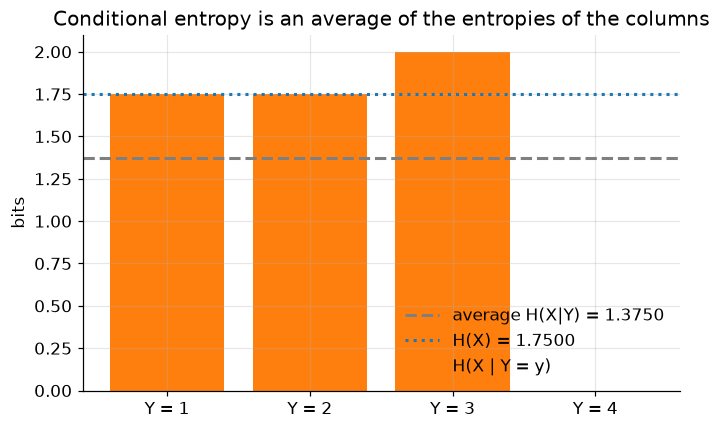

In [6]:
labels = [f"Y = {j+1}" for j in range(P.shape[1])]
plt.bar(labels, row_entropies, color=it.COLORS["cond"], label="H(X | Y = y)")
plt.axhline(H_X_g_Y, color=it.COLORS["bound"], linestyle="--",
            label=f"average H(X|Y) = {H_X_g_Y:.4f}")
plt.axhline(H_X, color=it.COLORS["H"], linestyle=":",
            label=f"H(X) = {H_X:.4f}")
plt.ylabel("bits")
plt.title("Conditional entropy is an average of the entropies of the columns")
plt.legend()
plt.show()

Notice that $H(X \mid Y = 3) = 2$ bits is *larger* than $H(X) = 1.75$ bits:
learning that $Y = 3$ makes $X$ more uncertain, not less. On the average,
however, $H(X \mid Y) = 1.375 < 1.75 = H(X)$. This is the point of
Theorem 2.6.5, treated in notebook 05.

## 2.4 The chain rule, Theorem 2.2.1

$$H(X,Y) = H(X) + H(Y \mid X) = H(Y) + H(X \mid Y).$$

In [7]:
print(f"H(X,Y)          = {H_XY:.6f}")
print(f"H(X) + H(Y|X)   = {H_X + H_Y_g_X:.6f}")
print(f"H(Y) + H(X|Y)   = {H_Y + H_X_g_Y:.6f}")

it.check("H(X,Y) = H(X) + H(Y|X)", np.isclose(H_XY, H_X + H_Y_g_X))
it.check("H(X,Y) = H(Y) + H(X|Y)", np.isclose(H_XY, H_Y + H_X_g_Y))

H(X,Y)          = 3.375000
H(X) + H(Y|X)   = 3.375000
H(Y) + H(X|Y)   = 3.375000
[PASS] H(X,Y) = H(X) + H(Y|X)
[PASS] H(X,Y) = H(Y) + H(X|Y)


True

The chain rule is not special to this table. The next cell checks it on two
thousand random joint distributions of various sizes.

In [8]:
n_tests = 2000
worst = 0.0
for _ in range(n_tests):
    nx, ny = rng.integers(2, 7), rng.integers(2, 7)
    Q = it.random_joint(nx, ny, rng)
    left = it.joint_entropy(Q)
    right = it.entropy(it.marginal_X(Q)) + it.cond_entropy_Y_given_X(Q)
    worst = max(worst, abs(left - right))

it.check(f"chain rule holds on {n_tests} random joint distributions",
         worst < 1e-9, f"largest discrepancy: {worst:.2e}")

[PASS] chain rule holds on 2000 random joint distributions   largest discrepancy: 1.78e-15


True

## 2.5 $H(Y \mid X)$ is not $H(X \mid Y)$, but the differences agree

The book's remark: $H(Y\mid X) \neq H(X \mid Y)$ in general, yet

$$H(X) - H(X \mid Y) = H(Y) - H(Y \mid X).$$

Both sides equal the mutual information $I(X;Y)$, the subject of notebook 03.

In [9]:
print(f"H(X) - H(X|Y) = {H_X - H_X_g_Y:.6f}")
print(f"H(Y) - H(Y|X) = {H_Y - H_Y_g_X:.6f}")
it.check("the two differences are equal",
         np.isclose(H_X - H_X_g_Y, H_Y - H_Y_g_X))
it.check("but H(X|Y) is different from H(Y|X)",
         not np.isclose(H_X_g_Y, H_Y_g_X),
         f"{H_X_g_Y:.4f} vs {H_Y_g_X:.4f}")

H(X) - H(X|Y) = 0.375000
H(Y) - H(Y|X) = 0.375000
[PASS] the two differences are equal
[PASS] but H(X|Y) is different from H(Y|X)   1.3750 vs 1.6250


True

## 2.6 The corollary with a third variable

$$H(X,Y \mid Z) = H(X \mid Z) + H(Y \mid X, Z).$$

With a 3-D table `P3[i, j, k]` $= p(x_i, y_j, z_k)$, every conditional entropy
is a difference of joint entropies, which makes this easy to check:

* $H(X,Y \mid Z) = H(X,Y,Z) - H(Z)$
* $H(X \mid Z) = H(X,Z) - H(Z)$
* $H(Y \mid X, Z) = H(X,Y,Z) - H(X,Z)$

In [10]:
P3 = rng.dirichlet(np.ones(3 * 4 * 2)).reshape(3, 4, 2)     # random p(x, y, z)

H_XYZ = it.entropy(P3)
H_Z   = it.entropy(P3.sum(axis=(0, 1)))
H_XZ  = it.entropy(P3.sum(axis=1))

H_XY_g_Z = H_XYZ - H_Z
H_X_g_Z  = H_XZ - H_Z
H_Y_g_XZ = H_XYZ - H_XZ

print(f"H(X,Y|Z)             = {H_XY_g_Z:.6f}")
print(f"H(X|Z) + H(Y|X,Z)    = {H_X_g_Z + H_Y_g_XZ:.6f}")
it.check("H(X,Y|Z) = H(X|Z) + H(Y|X,Z)",
         np.isclose(H_XY_g_Z, H_X_g_Z + H_Y_g_XZ))

H(X,Y|Z)             = 2.791306
H(X|Z) + H(Y|X,Z)    = 2.791306
[PASS] H(X,Y|Z) = H(X|Z) + H(Y|X,Z)


True

## 2.7 Estimating $H(Y \mid X)$ from data

Suppose we only observe pairs $(X_i, Y_i)$ and do not know $p(x,y)$. We can
count how often each pair occurs, divide by the number of samples, and feed
the resulting table to the same functions.

In [11]:
n = 50_000
nx, ny = P.shape

# draw n pairs from the book's table
flat_index = rng.choice(nx * ny, size=n, p=P.ravel())
x_samples, y_samples = np.divmod(flat_index, ny)

counts = np.zeros((nx, ny))
for i, j in zip(x_samples, y_samples):
    counts[i, j] += 1
P_hat = counts / n

print("estimated table:")
it.show_table(P_hat)
print()
print(f"estimated H(Y|X) = {it.cond_entropy_Y_given_X(P_hat):.4f}"
      f"   true = {H_Y_g_X:.4f}")
print(f"estimated H(X|Y) = {it.cond_entropy_X_given_Y(P_hat):.4f}"
      f"   true = {H_X_g_Y:.4f}")

estimated table:
X\Y           1        2        3        4       p(x)
    1    0.1258   0.0607   0.0638   0.2496     0.4999
    2    0.0606   0.1243   0.0620   0.0000     0.2470
    3    0.0326   0.0311   0.0622   0.0000     0.1259
    4    0.0328   0.0313   0.0631   0.0000     0.1273
 p(y)    0.2518   0.2474   0.2512   0.2496     1.0000

estimated H(Y|X) = 1.6250   true = 1.6250
estimated H(X|Y) = 1.3783   true = 1.3750


## 2.8 A picture of the decomposition

The chain rule says the bar of total length $H(X,Y)$ splits in two ways.

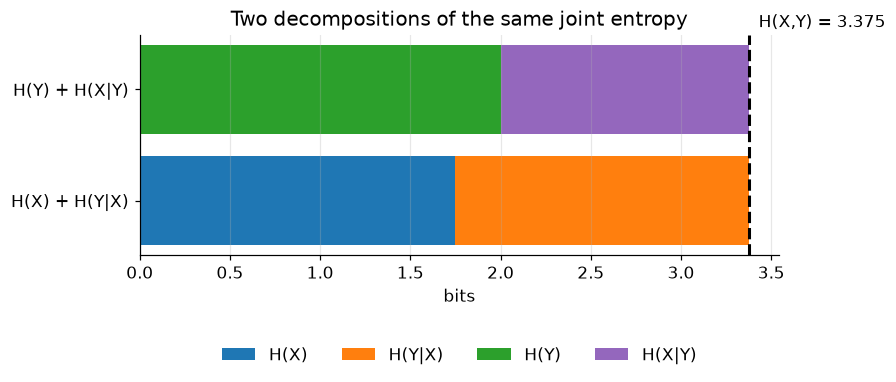

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.barh(["H(X) + H(Y|X)"], [H_X], color=it.COLORS["H"], label="H(X)")
ax.barh(["H(X) + H(Y|X)"], [H_Y_g_X], left=[H_X],
        color=it.COLORS["cond"], label="H(Y|X)")
ax.barh(["H(Y) + H(X|Y)"], [H_Y], color=it.COLORS["I"], label="H(Y)")
ax.barh(["H(Y) + H(X|Y)"], [H_X_g_Y], left=[H_Y],
        color=it.COLORS["extra"], label="H(X|Y)")
ax.axvline(H_XY, color="black", linestyle="--")
ax.text(H_XY, 1.6, f"  H(X,Y) = {H_XY:.3f}", va="center")
ax.set_xlabel("bits")
ax.set_title("Two decompositions of the same joint entropy")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.35))
ax.grid(axis="y", visible=False)
plt.show()

## Things to try

1. Replace the book's table by one in which $Y$ is a function of $X$
   (each row has a single non-zero entry). Check that $H(Y \mid X) = 0$ and
   that $H(X,Y) = H(X)$.
2. Replace it by a product table `P = np.outer(px, py)`. Check that
   $H(X \mid Y) = H(X)$ and $H(X,Y) = H(X) + H(Y)$.
3. Build a table where $H(X \mid Y) > H(Y \mid X)$ and one where the reverse
   holds. What feature of the table controls which is larger?
4. In Section 2.7, reduce `n` to 200 and re-run several times. How unstable is
   the estimate of $H(Y \mid X)$? Which cell of the table causes most of the
   trouble?